**Name:** Hardik Borse

**Roll no.:** BEBD23268

## CL-1 Lab Assignment 2 (Group A): Regression Analysis
### Statistical and Regression Analysis of Diabetes Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import skew, kurtosis
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

plt.rcParams["figure.figsize"] = (10, 6)

In [ ]:
# Importing Dataset
pima_file = "diabetes.csv"
pima = pd.read_csv(pima_file)

print("Pima dataset shape:", pima.shape)
display(pima.head())

Pima dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


In [2]:
print("Columns:")
print(pima.columns.tolist())

print("\nData types:")
display(pima.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(pima.isna().sum().to_frame("missing"))

print("\nSummary statistics:")
display(pima.describe().T)

print("\nOutcome frequency:")
display(pima["Outcome"].value_counts().sort_index().to_frame("Frequency"))

Columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Data types:


,dtype
Pregnancies,int64
Glucose,int64
BloodPressure,float64
SkinThickness,int64
Insulin,float64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64



Missing values:


,missing
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,121.677083,30.464161,44.000,99.75000,117.0000,140.25000,199.00
BloodPressure,768.0,72.389323,12.106039,24.000,64.00000,72.0000,80.00000,122.00
SkinThickness,768.0,29.089844,8.890820,7.000,25.00000,28.0000,32.00000,99.00
Insulin,768.0,141.753906,89.100847,14.000,102.50000,102.5000,169.50000,846.00
BMI,768.0,32.434635,6.880498,18.200,27.50000,32.0500,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00



Outcome frequency:


,Frequency
Outcome,
0,500
1,268


In [3]:
categorical_cols = ["Outcome"]

for col in categorical_cols:
    print(f"Frequency table for {col}:")
    display(pima[col].value_counts().sort_index().to_frame("Frequency"))

Frequency table for Outcome:


,Frequency
Outcome,
0,500
1,268


In [4]:
# Frequency tables for selected numeric variables after binning.
selected_for_frequency = ["Pregnancies", "Glucose", "BMI", "Age"]

for col in selected_for_frequency:
    if col in pima.columns:
        print(f"\nFrequency distribution for {col}:")
        display(pima[col].value_counts().sort_index().head(20).to_frame("Frequency"))


Frequency distribution for Pregnancies:


,Frequency
Pregnancies,
0,111
1,135
2,103
3,75
4,68
5,57
6,50
7,45
8,38



Frequency distribution for Glucose:


,Frequency
Glucose,
44,1
56,1
57,2
61,1
62,1
65,1
67,1
68,3
71,4



Frequency distribution for BMI:


,Frequency
BMI,
18.2,3
18.4,1
19.1,1
19.3,1
19.4,1
19.5,2
19.6,3
19.9,1
20.0,1



Frequency distribution for Age:


,Frequency
Age,
21,63
22,72
23,38
24,46
25,48
26,33
27,32
28,35
29,29


### Univariate Analysis - Mean, Median, Mode, Variance, SD, Skewness and Kurtosis

In [5]:
numeric_cols = pima.select_dtypes(include=np.number).columns

stats = pd.DataFrame({
    "Mean": pima[numeric_cols].mean(),
    "Median": pima[numeric_cols].median(),
    "Mode": pima[numeric_cols].mode().iloc[0],
    "Variance": pima[numeric_cols].var(),
    "Std_Deviation": pima[numeric_cols].std(),
    "Skewness": pima[numeric_cols].skew(),
    "Kurtosis": pima[numeric_cols].kurt()
})

display(stats.round(4))

,Mean,Median,Mode,Variance,Std_Deviation,Skewness,Kurtosis
Pregnancies,3.8451,3.0000,1.000,11.3541,3.3696,0.9017,0.1592
Glucose,121.6771,117.0000,99.000,928.0651,30.4642,0.5323,-0.2681
BloodPressure,72.3893,72.0000,70.000,146.5562,12.1060,0.1408,1.0854
SkinThickness,29.0898,28.0000,27.000,79.0467,8.8908,0.8175,5.0676
Insulin,141.7539,102.5000,102.500,7938.9609,89.1008,3.0280,13.8530
BMI,32.4346,32.0500,30.100,47.3412,6.8805,0.6064,0.9155
DiabetesPedigreeFunction,0.4719,0.3725,0.254,0.1098,0.3313,1.9199,5.5950
Age,33.2409,29.0000,22.000,138.3030,11.7602,1.1296,0.6432
Outcome,0.3490,0.0000,0.000,0.2275,0.4770,0.6350,-1.6009


### Distribution Visualizations

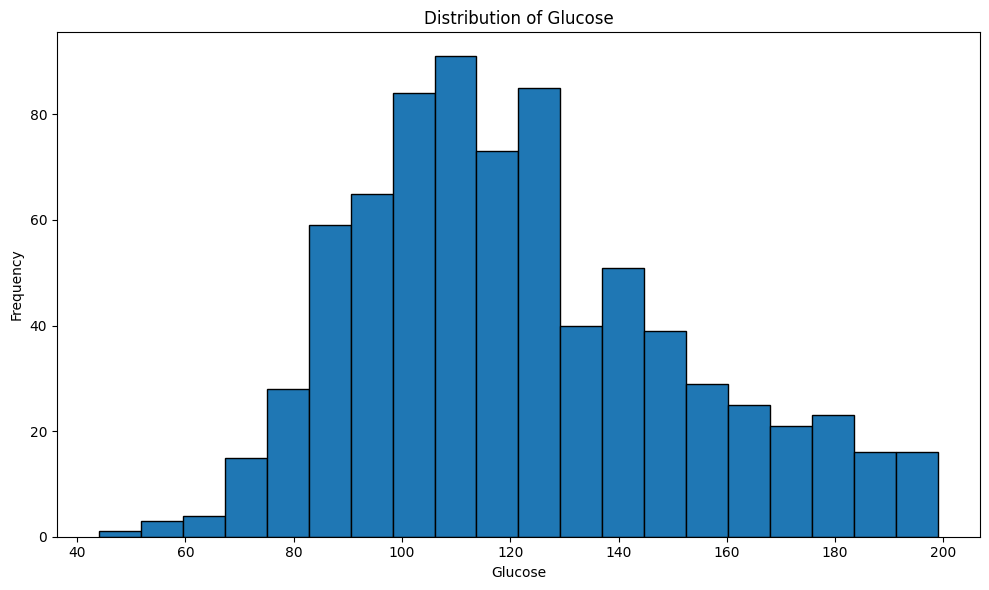

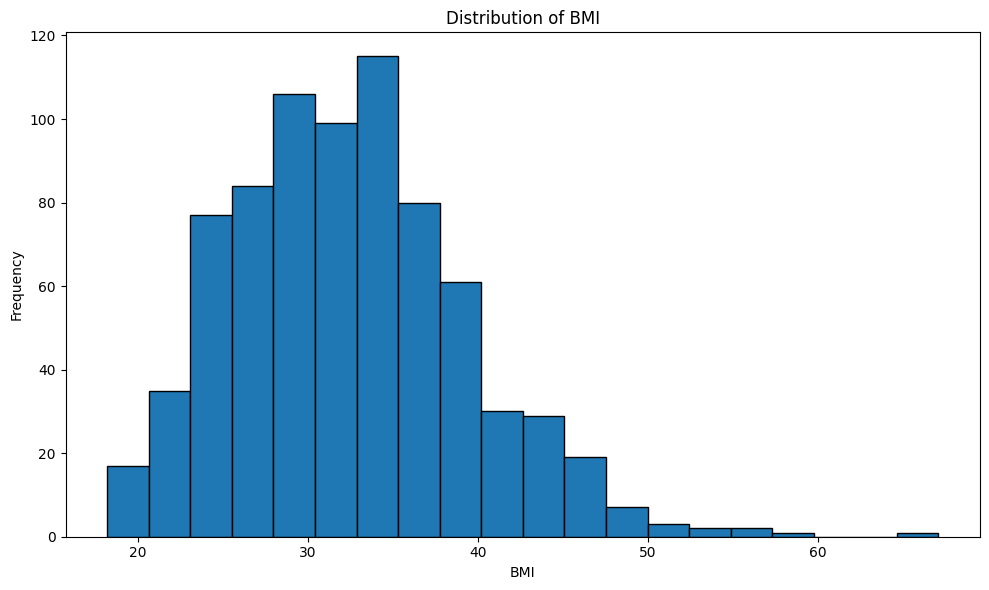

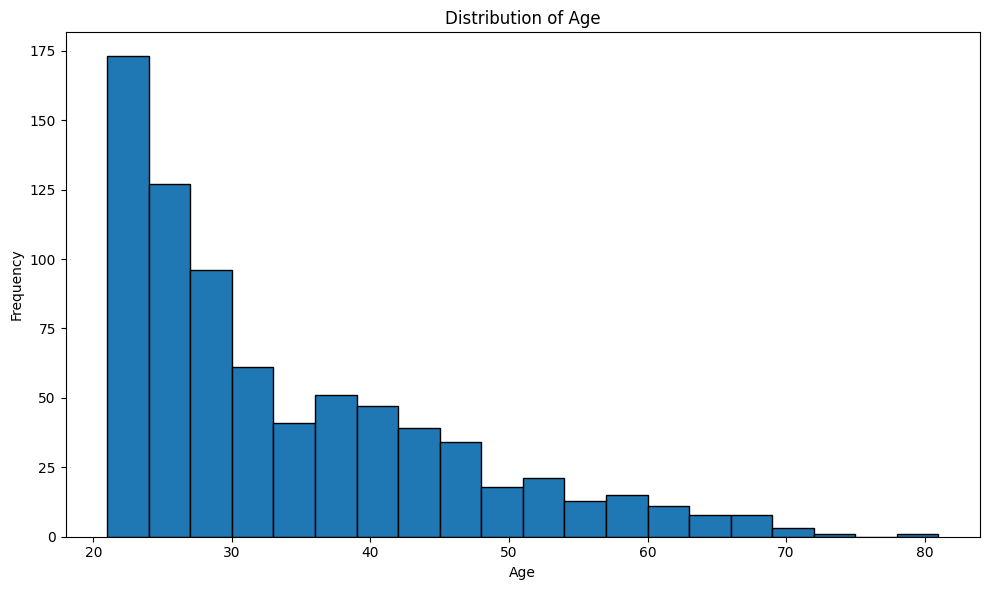

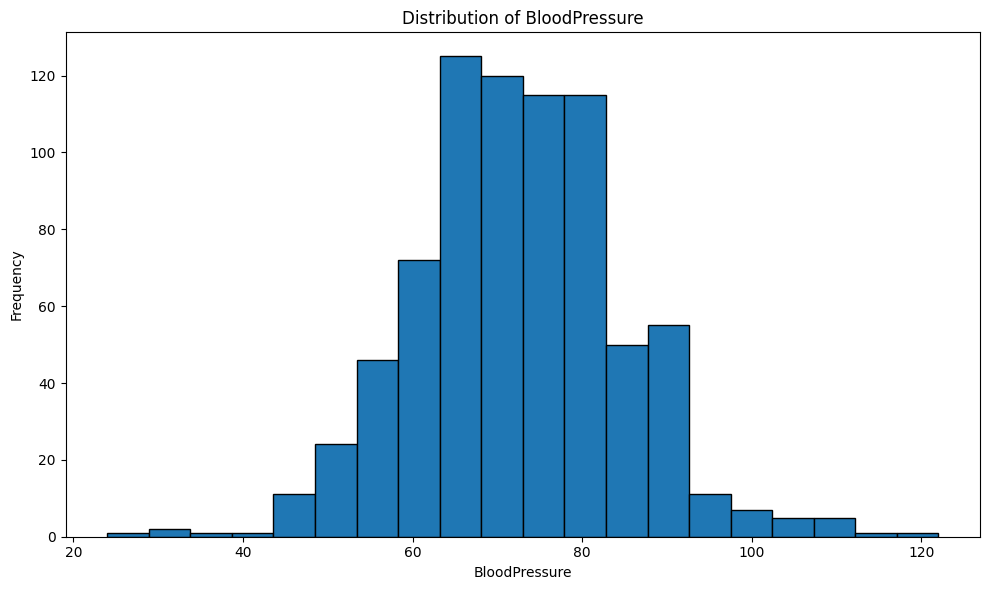

In [6]:
for col in ["Glucose", "BMI", "Age", "BloodPressure"]:
    plt.figure()
    plt.hist(pima[col].dropna(), bins=20, edgecolor="black")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

### Bivariate Analysis - Linear Regression

In [ ]:
# Glucose as predictor and BMI as continuous response.
X_linear = pima[["Glucose"]]
y_linear = pima["BMI"]

linear_model = LinearRegression()
linear_model.fit(X_linear, y_linear)

linear_pred = linear_model.predict(X_linear)

print("Linear regression equation:")
print(f"BMI = {linear_model.intercept_:.4f} + ({linear_model.coef_[0]:.4f}) * Glucose")
print(f"R²: {r2_score(y_linear, linear_pred):.4f}")
print(f"MAE: {mean_absolute_error(y_linear, linear_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_linear, linear_pred)):.4f}")

Linear regression equation:
BMI = 25.9443 + (0.0533) * Glucose
R²: 0.0558
MAE: 5.2844
RMSE: 6.6815


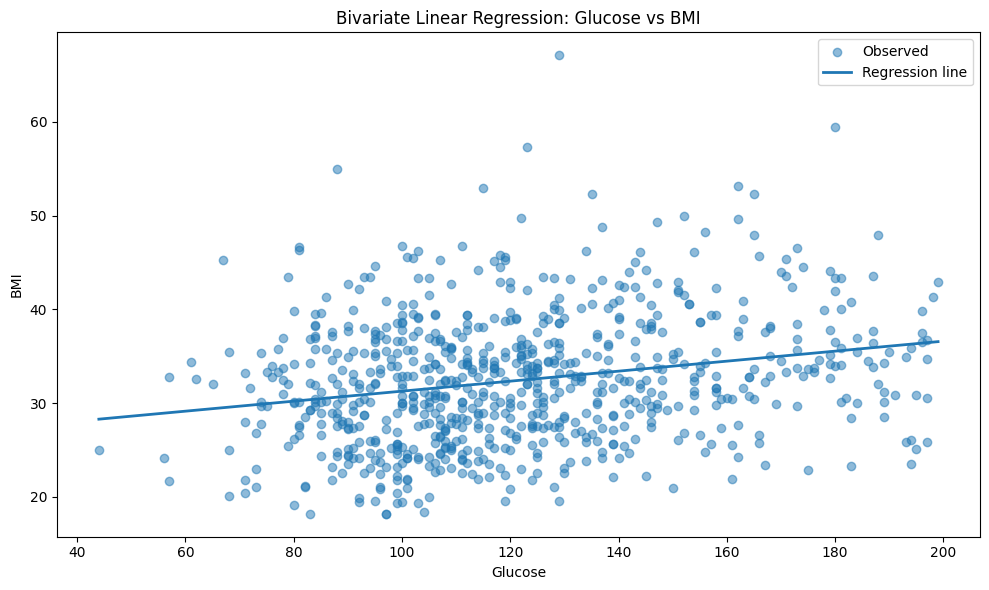

In [8]:
plt.figure()
plt.scatter(pima["Glucose"], pima["BMI"], alpha=0.5, label="Observed")
order = np.argsort(pima["Glucose"].values)
plt.plot(
    pima["Glucose"].values[order],
    linear_pred[order],
    linewidth=2,
    label="Regression line"
)
plt.title("Bivariate Linear Regression: Glucose vs BMI")
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.legend()
plt.tight_layout()
plt.show()

### Bivariate Analysis - Logistic Regression

In [9]:
# Logistic regression: predict diabetes Outcome using Glucose alone.
X_log = pima[["Glucose"]]
y_log = pima["Outcome"]

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_log, y_log)

log_prob = log_model.predict_proba(X_log)[:, 1]
log_pred = log_model.predict(X_log)

print(f"Coefficient: {log_model.coef_[0][0]:.6f}")
print(f"Intercept: {log_model.intercept_[0]:.6f}")
print(f"Accuracy: {accuracy_score(y_log, log_pred):.4f}")
print(f"Precision: {precision_score(y_log, log_pred, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_log, log_pred, zero_division=0):.4f}")
print(f"F1 Score: {f1_score(y_log, log_pred, zero_division=0):.4f}")

Coefficient: 0.040924
Intercept: -5.748833
Accuracy: 0.7448
Precision: 0.6875
Recall: 0.4925
F1 Score: 0.5739


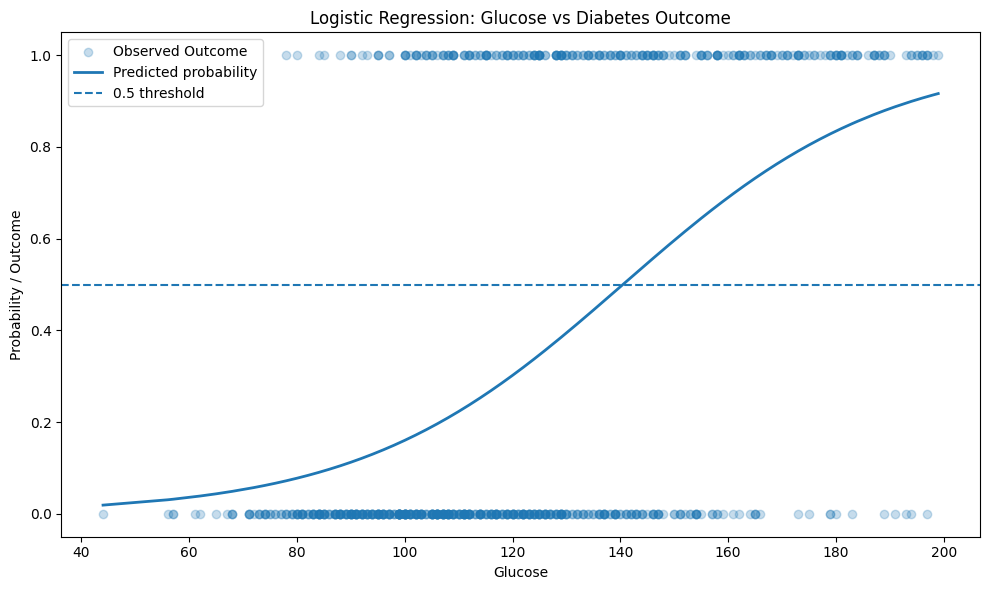

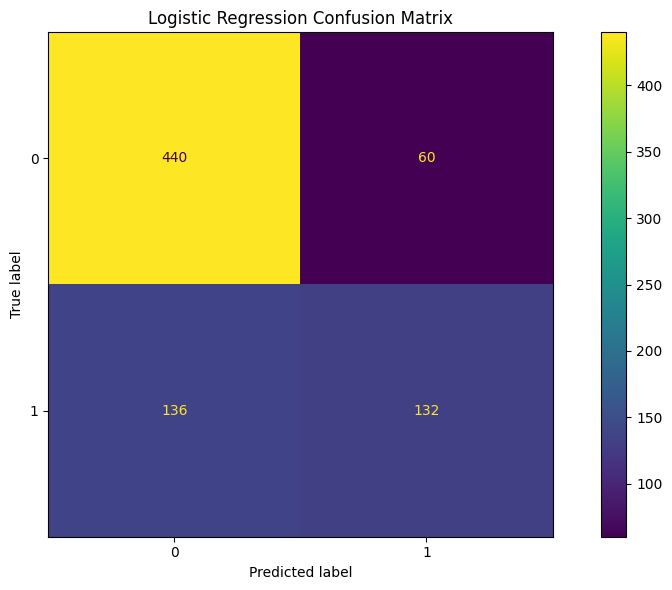

In [10]:
plt.figure()
plt.scatter(pima["Glucose"], y_log, alpha=0.25, label="Observed Outcome")

order = np.argsort(pima["Glucose"].values)
plt.plot(
    pima["Glucose"].values[order],
    log_prob[order],
    linewidth=2,
    label="Predicted probability"
)

plt.axhline(0.5, linestyle="--", label="0.5 threshold")
plt.title("Logistic Regression: Glucose vs Diabetes Outcome")
plt.xlabel("Glucose")
plt.ylabel("Probability / Outcome")
plt.legend()
plt.tight_layout()
plt.show()

ConfusionMatrixDisplay.from_predictions(y_log, log_pred)
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

### Multivariate Analysis: Multiple Linear Regression

In [11]:
# Predict BMI using several continuous/numeric patient measurements.
multiple_features = [
    "Pregnancies", "Glucose", "BloodPressure",
    "SkinThickness", "Insulin",
    "DiabetesPedigreeFunction", "Age"
]

X_multi = pima[multiple_features]
y_multi = pima["BMI"]

multi_model = LinearRegression()
multi_model.fit(X_multi, y_multi)

multi_pred = multi_model.predict(X_multi)

coefficients = pd.DataFrame({
    "Feature": multiple_features,
    "Coefficient": multi_model.coef_
})

display(coefficients)

print(f"Intercept: {multi_model.intercept_:.4f}")
print(f"R²: {r2_score(y_multi, multi_pred):.4f}")
print(f"MAE: {mean_absolute_error(y_multi, multi_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_multi, multi_pred)):.4f}")

,Feature,Coefficient
0,Pregnancies,-0.004227
1,Glucose,0.010578
2,BloodPressure,0.120826
3,SkinThickness,0.387467
4,Insulin,0.008100
5,DiabetesPedigreeFunction,1.710836
6,Age,-0.078005


Intercept: 11.7834
R²: 0.3892
MAE: 4.1826
RMSE: 5.3738


### Multiple Logistic Regression

Accuracy: 0.7013
Precision: 0.5833
Recall: 0.5185
F1 Score: 0.5490


,Feature,Coefficient
0,Pregnancies,0.094254
1,Glucose,0.031305
2,BloodPressure,0.008064
3,SkinThickness,0.059567
4,Insulin,0.008568
5,DiabetesPedigreeFunction,0.561607
6,Age,0.008158


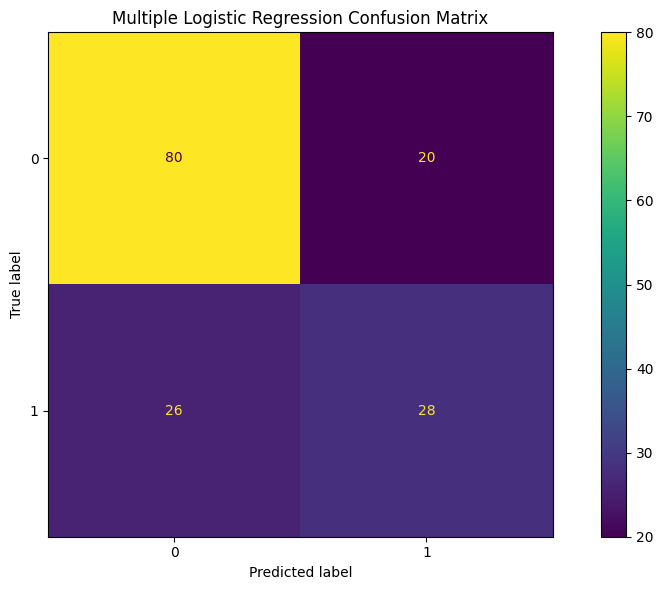

In [12]:
# Multiple logistic regression for the binary diabetes Outcome.
X_ml = pima[multiple_features]
y_ml = pima["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X_ml, y_ml,
    test_size=0.20,
    random_state=42,
    stratify=y_ml
)

multiple_log = LogisticRegression(max_iter=2000)
multiple_log.fit(X_train, y_train)

multi_log_pred = multiple_log.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, multi_log_pred):.4f}")
print(f"Precision: {precision_score(y_test, multi_log_pred, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test, multi_log_pred, zero_division=0):.4f}")
print(f"F1 Score: {f1_score(y_test, multi_log_pred, zero_division=0):.4f}")

display(pd.DataFrame({
    "Feature": multiple_features,
    "Coefficient": multiple_log.coef_[0]
}))

ConfusionMatrixDisplay.from_predictions(y_test, multi_log_pred)
plt.title("Multiple Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()